In [1]:
import pickle
import json
import torch
import pandas as pd
import os

from post_analysis import *

/opt/anaconda3/envs/firegnn/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_pickle(filepath):
    with open(filepath, 'rb') as f:
        obj = pickle.load(f)
    return obj

def load_json(filepath):
    with open(filepath, 'rb') as f:
        obj = json.load(f)
    return obj

In [3]:
result_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/results.pkl"
rule_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/cv_fuzzy_rules.pkl"
param_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/GAT/cv_fuzzy_params.pkl"
meta_path = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/graph_meta.json"

result = load_pickle(result_path)
fuzzy_rule = load_pickle(rule_path)
fuzzy_params = load_pickle(param_path) 
meta = load_json(meta_path)

In [4]:
patients = meta['patients']
rule_names = meta['rule_names']
direct_names = meta['direct_rule_names']
topo_names = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']

In [7]:
def parse_rule_activations(result_path:str, meta_path)->pd.DataFrame:
    # load result and meta
    with open(result_path, 'rb') as f:
        result = pickle.load(f)
    with open(meta_path, 'rb') as f:
        meta = json.load(f)
    
    patients = meta['patients']
    rule_names = meta['rule_names']
    direct_names = meta['direct_rule_names']
    topo_names = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']
    
    # extract rule_activations for all samples of all folds in one backbone model 
    rule_dfs = []
    for model_type, res in result.items():
        
        res_rules = res.get('fuzzy_rules')
        res_params = res.get('fuzzy_params')
        if isinstance(res_rules, list) and len(res_rules) !=0:
            for fold_idx, rules in enumerate(res_rules):
                if rules is None: # or not isinstance(rules, torch.Tensor):
                    continue
                
                # get rule activations 
                num_rules = rules.size(1)
                # print(rules.size())
                df = pd.DataFrame(rules)
                if num_rules == 5:
                    df.columns = topo_names
                elif num_rules == 185:
                    df.columns = direct_names
                elif num_rules == 190:
                    df.columns = topo_names + direct_names
                elif num_rules == 741:
                    df.columns = rule_names
                else:
                    df.columns = topo_names + rule_names
                df.insert(loc=0, column='sample_id', value=patients)
                df.insert(loc=1, column='model', value=model_type)
                df.insert(loc=2,column='fold',value=fold_idx+1)
            
                rule_dfs.append(df)

    df_rule_activation = pd.concat(rule_dfs, axis=0)
    return df_rule_activation

In [8]:
# parse root folder to get all rule actiavtion for all backbone models
def parse_all_rule_activations(root_dir:str, output_dir:Optional[str]=None):
    activation_dfs = []
    for dirpath, _, filenames in os.walk(root_dir):
        
        # root_dir/dataset/k/backbone/results.pkl
        if 'results.pkl' not in filenames:
            continue
        result_path = os.path.join(dirpath,'results.pkl')

        # Calculate meta_path by going exactly one directory up from 'backbone' to 'k'
        parent_dir = os.path.dirname(dirpath)
        meta_path = os.path.join(parent_dir, 'graph_meta.json')
        
        # Safety check to ensure the meta file actually exists before processing
        if not os.path.exists(meta_path):
            print(f"Warning: Missing graph_meta.json for {result_path}. Skipping.")
            continue

        rel=os.path.relpath(dirpath, root_dir)
        parts = rel.split(os.sep)

        if len(parts) < 3:
            continue
        dataset=parts[0]
        k=parts[1]
        backbone=parts[2]

        df = parse_rule_activations(result_path, meta_path)
        df.insert(loc=3, column='dataset', value=dataset)
        df.insert(loc=4, column='k', value=k)
        df.insert(loc=5,column='backbone',value=backbone)
        activation_dfs.append(df)
    
    # Combine everything
    if activation_dfs:
        df_rule_activation = pd.concat(activation_dfs, axis=0, ignore_index=True)
    else:
        print("No valid result files found.")
        return pd.DataFrame()
        
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        df_rule_activation.to_csv(os.path.join(output_dir, 'df_samplewise_rule_activations.csv'))
    
    return df_rule_activation

In [5]:
root_dir= "../nesy_gnn/results/explain/AD_KG"
output_dir = "../nesy_gnn/results/explain/AD_KG/rules"
df_all_activation = parse_all_rule_activations(root_dir, output_dir)

df_all_activation

,sample_id,model,fold,dataset,k,backbone,degrees,clustering,eigenvector_centrality,degree_centrality,...,chain_RAC1_5hops_CTL,chain_RAC1_5hops_AD,chain_RAC1_4hops_AD,chain_AKAP13_5hops_AD,chain_AKAP13_5hops_CTL,chain_AKAP13_4hops_AD,chain_VPS35_5hops_AD,chain_VPS35_5hops_CTL,chain_VPS35_4hops_AD,chain_GRN_3hops_AD
0,DCR00001_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.443283,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.552419,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.612887,0.518729,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,0.511766,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.852141,0.923173,0.487230,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.332155,0.960963,0.419785,0.329545,...,0.683675,0.684229,0.682762,0.686348,0.686427,0.685961,0.724487,0.725035,0.725473,0.581494
69096,TLSMCI608_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.578092,0.828952,0.419785,0.580268,...,0.747017,0.747404,0.746337,0.839109,0.839582,0.838211,0.752516,0.753009,0.753426,0.833568
69097,TLSMCI609_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.410801,0.621224,0.432282,0.409620,...,0.262853,0.263923,0.261337,0.271425,0.270232,0.273024,0.356357,0.357228,0.357609,0.236438
69098,TLSMCI611_1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.935808,0.351296,0.646809,0.939164,...,0.264917,0.265989,0.263397,0.303512,0.302356,0.305036,0.282792,0.283609,0.283923,0.320413


In [5]:
# load df_ig_attributions
df_attributions = pd.read_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/df_samplewise_rule_attributions.csv", 
                              index_col=0)
df_attributions = df_attributions.reset_index()
df_attributions

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_48251/40901504.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_attributions = df_attributions.reset_index()


,sample_id,Label,Prediction,gate,fold,model,dataset,k,backbone,degrees,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,1,1,0.508388,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000098,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,1,1,0.484337,1,FuzzyGAT_topo,ANMerge,4,GAT,0.000030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,0,1,0.458731,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000094,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,0,1,0.500154,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,0,0,0.476903,1,FuzzyGAT_topo,ANMerge,4,GAT,0.000111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,1,1,0.702342,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.001858,...,0.001489,0.003278,0.001061,0.002879,0.001547,0.002417,-0.001478,-0.000923,-0.000168,-0.000324
69096,TLSMCI608_1,1,1,0.712895,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,0.000887,...,0.002209,0.001674,0.000589,0.001162,0.000988,0.001966,-0.001192,-0.001491,0.000144,-0.000661
69097,TLSMCI609_1,1,1,0.657470,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.000961,...,-0.002652,-0.002672,-0.000680,-0.001832,-0.001389,-0.002235,0.001510,0.001049,0.000559,0.000326
69098,TLSMCI611_1,1,0,0.676286,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.002036,...,0.000389,0.000244,0.000341,-0.000536,-0.000438,0.000773,-0.001326,0.000792,-0.000058,0.000886


Top-5 rule_name by DCR00001_1:
['direct_TNFRSF1B_CTL', 'chain_MMP9_APP_CTL', 'chain_FOXO4_insulin receptor sig_CTL', 'chain_SNCA_MAPT_AD', 'direct_IRS2_CTL']


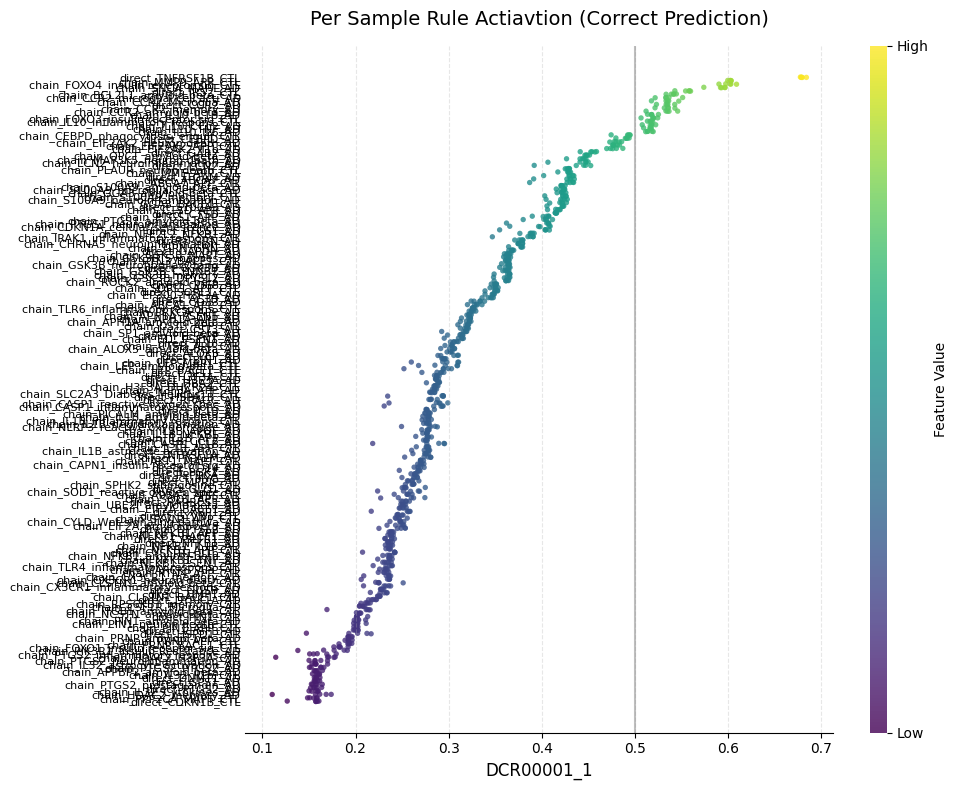

Top-5 rule_name by DCR00009_1:
['chain_IL10_CCL2_AD', 'chain_IL10_inflammatory respons_CTL', 'chain_IL10_IL1B_AD', 'chain_IL10_IL6_AD', 'chain_IL10_TNF_AD']


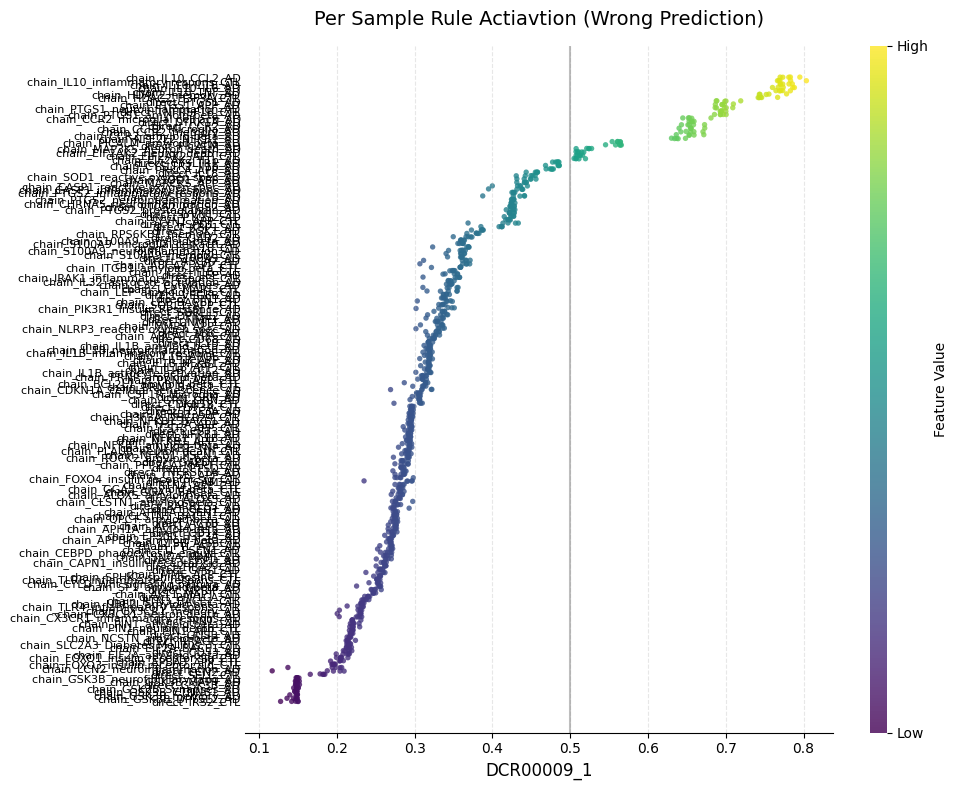

In [ ]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"

plot_df = df_all_activation[(df_all_activation['model']==model_type) &
                            (df_all_activation['dataset']==dataset) &
                            (df_all_activation['k'] == str(k))
                            ]

if 'sample_id' not in plot_df.columns and plot_df.index.name=='sample_id':
    plot_df.reset_index()
non_rule_cols = ['model', 'fold', 'dataset', 'k', 'backbone', 'Label', 'Prediction']
rule_cols = [col for col in plot_df.columns if col not in non_rule_cols]

plot_df = plot_df[rule_cols]

# melt
melted = plot_df.melt(id_vars='sample_id', var_name='rule_name', value_name='activation')
melted['occ'] = melted.groupby(['sample_id', 'rule_name']).cumcount()

new_df = melted.pivot(index=['rule_name','occ'], columns='sample_id', values='activation').reset_index()
new_df = new_df.drop(columns=['occ']).dropna()

df_plot1 = plot_rule_importance(df=new_df,
                            x_col='DCR00001_1',
                            y_col='rule_name',
                            title='Per Sample Rule Actiavtion (Correct Prediction)',
                            cmap='viridis',
                            central_vertical_line=0.5,
                            interpolate=False,
                            )

df_plot2 = plot_rule_importance(df=new_df,
                            x_col='DCR00009_1',
                            y_col='rule_name',
                            title='Per Sample Rule Actiavtion (Wrong Prediction)',
                            cmap='viridis',
                            central_vertical_line=0.5,
                            interpolate=False,
                            )

Top-5 rule_name by DCR00013_1:
['direct_TNFRSF1B_CTL', 'chain_CX3CR1_memory_AD', 'chain_CX3CR1_neuron death_AD', 'chain_CX3CR1_inflammatory respons_AD', 'chain_CCR2_microglial cell acti_AD']


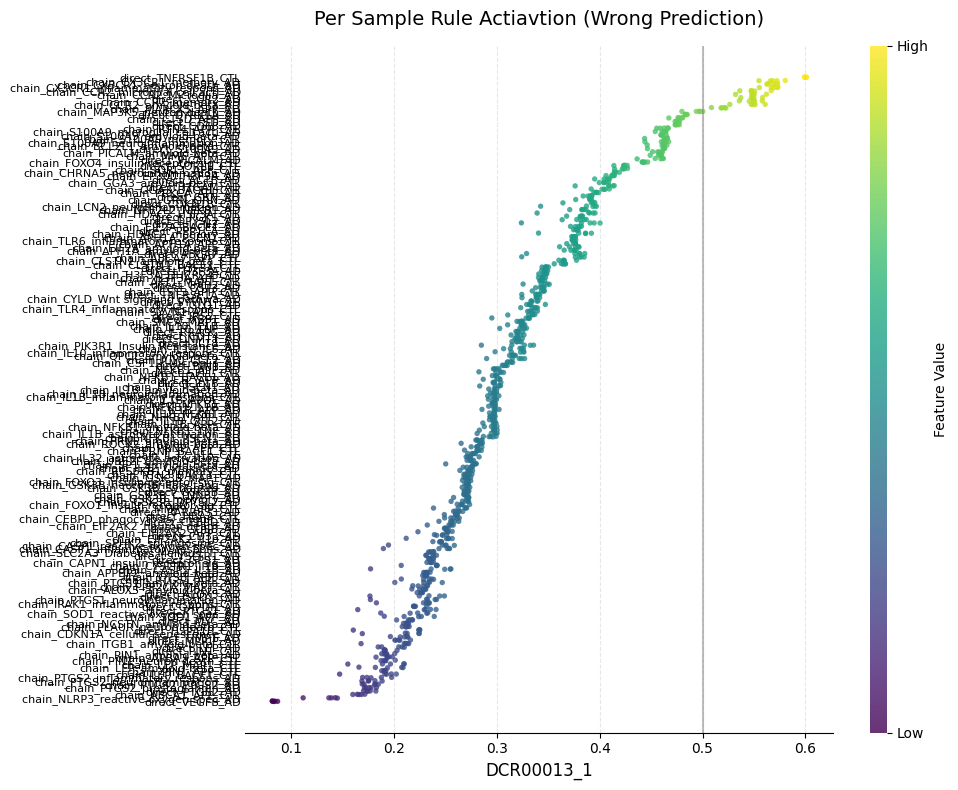

In [ ]:
df_plot2 = plot_rule_importance(df=new_df,
                            x_col='DCR00013_1',
                            y_col='rule_name',
                            title='Per Sample Rule Actiavtion (Wrong Prediction)',
                            cmap='viridis',
                            central_vertical_line=0.5,
                            interpolate=False,
                            )

In [20]:
df_sample1 = df_plot1[df_plot1['DCR00001_1']>0.5]
df_sample1 = df_sample1.sort_values(by='DCR00001_1', ascending=False)
df_sample1['rule_name'].unique()

<StringArray>
[                 'direct_TNFRSF1B_CTL',
 'chain_FOXO4_insulin receptor sig_CTL',
                   'chain_MMP9_APP_CTL',
                   'chain_SNCA_MAPT_AD',
                      'direct_IRS2_CTL',
   'chain_CCR2_microglial cell acti_AD',
              'chain_CCR2_Microglia_AD',
           'chain_CCR2_amyloid-beta_AD',
        'chain_BCL2L1_amyloid-beta_CTL',
                 'chain_CCR2_memory_AD',
                       'direct_CCR2_AD',
                   'chain_IL10_IL1B_AD',
 'chain_FOXO3_insulin receptor sig_CTL',
                   'chain_IL10_CCL2_AD',
                    'chain_IL10_IL6_AD',
  'chain_IL10_inflammatory respons_CTL',
                    'chain_IL10_TNF_AD']
Length: 17, dtype: str

In [24]:
df_sample2 = df_plot2[df_plot2['DCR00013_1']>0.5]
df_sample2 = df_sample2.sort_values(by='DCR00013_1', ascending=False)
df_sample2['rule_name'].unique()

<StringArray>
[                 'direct_TNFRSF1B_CTL',
               'chain_CX3CR1_memory_AD',
 'chain_CX3CR1_inflammatory respons_AD',
         'chain_CX3CR1_neuron death_AD',
   'chain_CCR2_microglial cell acti_AD',
              'chain_CCR2_Microglia_AD',
           'chain_CCR2_amyloid-beta_AD',
                       'direct_CCR2_AD',
                 'chain_CCR2_memory_AD',
                  'chain_MARCKS_APP_AD',
         'chain_MAP3K5_neuron death_AD']
Length: 11, dtype: str

# Rule Activations on Prediction Correctness Stratification (True/False Prediction Groups)

In [2]:
df_all_activation = pd.read_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/df_samplewise_rule_activations.csv",
                                index_col=0)

if 'Label' not in df_all_activation.columns:
    # 1. Create the dictionaries from df1
    pred_dict = dict(zip(df_attributions['sample_id'], df_attributions['Prediction']))
    label_dict = df_attributions.set_index('sample_id')['Label'].to_dict()

    # 2. Map them to df2
    df_all_activation.insert(loc=1, column='Label', value=df_all_activation['sample_id'].map(label_dict)) 
    df_all_activation.insert(loc=2, column='Prediction', value=df_all_activation['sample_id'].map(pred_dict))
    df_all_activation.to_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/df_samplewise_rule_activations.csv")
df_all_activation

,sample_id,Label,Prediction,model,fold,dataset,k,backbone,degrees,clustering,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,1,1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,1,1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,0,1,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.612887,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,0,0,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.453497,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,0,0,FuzzyGAT_topo,1,ANMerge,4,GAT,0.486002,0.852141,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,1,1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.332155,0.960963,...,0.683675,0.684229,0.682762,0.686348,0.686427,0.685961,0.724487,0.725035,0.725472,0.581494
69096,TLSMCI608_1,1,1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.578092,0.828952,...,0.747017,0.747404,0.746337,0.839109,0.839582,0.838211,0.752516,0.753009,0.753426,0.833568
69097,TLSMCI609_1,1,1,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.410801,0.621224,...,0.262853,0.263923,0.261337,0.271425,0.270232,0.273024,0.356357,0.357228,0.357609,0.236438
69098,TLSMCI611_1,1,0,FuzzyGIN_topo_all_rules,5,ANMerge,4,GIN,0.935808,0.351296,...,0.264917,0.265989,0.263397,0.303512,0.302356,0.305036,0.282792,0.283609,0.283923,0.320413


/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:953: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:955: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation_score:
['chain_EIF2AK2_neuron death_AD', 'chain_EIF2AK2_APP_CTL', 'chain_EIF2AK2_Il1b_AD', 'direct_GAB2_AD', 'chain_IL32_Il1b_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/ANMerge_FuzzyGAT_direct_rules_mean_activation_score_True Prediction.png


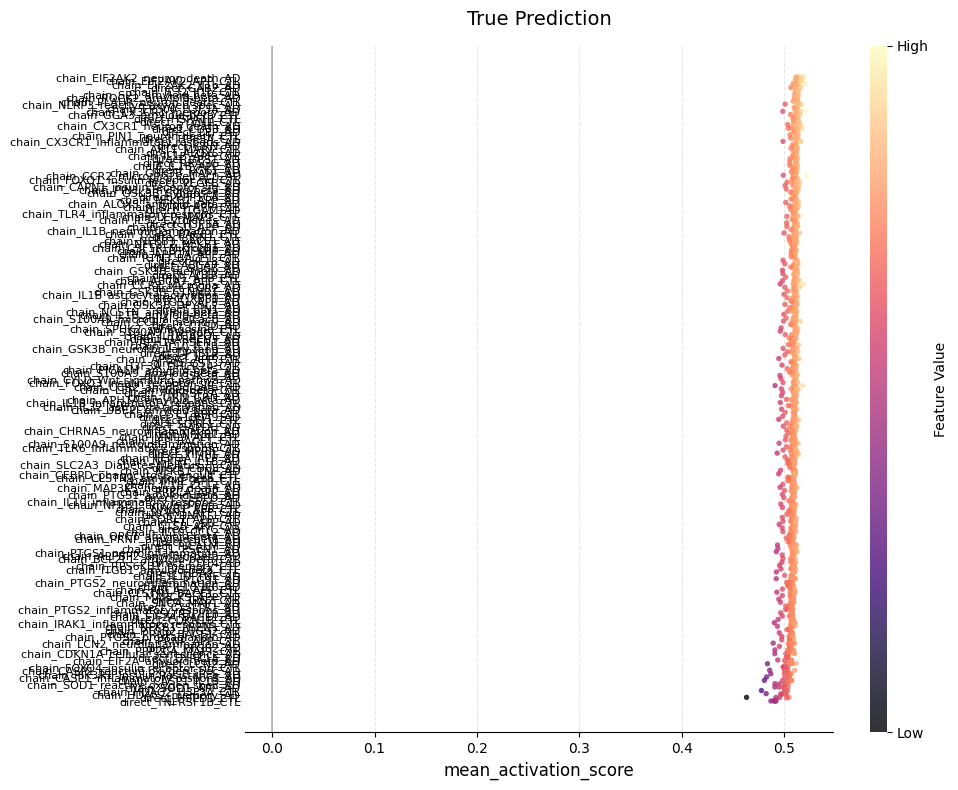

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:953: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:955: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation_score:
['direct_TNFRSF1B_CTL', 'chain_FOXO4_insulin receptor sig_CTL', 'chain_CCR2_microglial cell acti_AD', 'chain_CCR2_Microglia_AD', 'direct_CCR2_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/ANMerge_FuzzyGAT_direct_rules_mean_activation_score_False Prediction.png


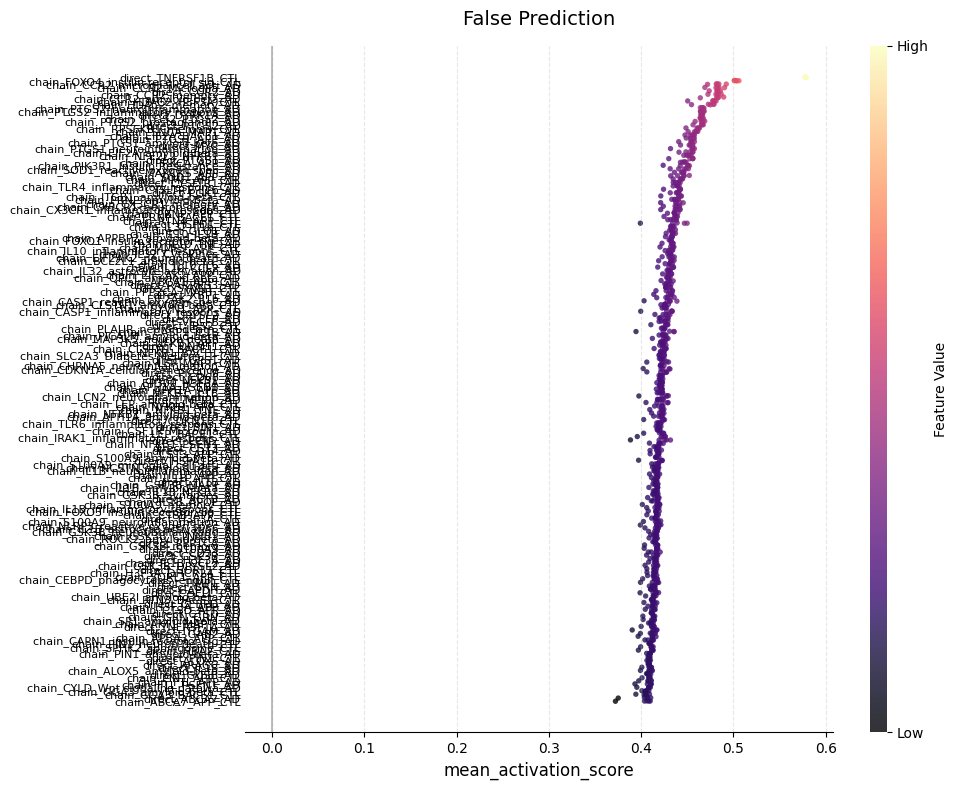

In [9]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"
save_dir = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules"

df_direct_t = plot_wrong_correct_mean_rulescore(df_samples=df_all_activation, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name='mean_activation_score',
                                        plot_correct=True,
                                        cmap='magma',
                                        save_dir=save_dir)

df_direct_f = plot_wrong_correct_mean_rulescore(df_samples=df_all_activation, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name='mean_activation_score',
                                        plot_correct=False,
                                        cmap='magma',
                                        save_dir=save_dir)

+ All rules variant

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:953: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:955: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation_score:
['avg_edge_weight', 'chain_ARRB2_4hops_AD', 'chain_ARRB2_5hops_AD', 'chain_ARRB2_5hops_CTL', 'chain_NLRP3_5hops_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/ANMerge_FuzzyGAT_topo_all_rules_mean_activation_score_True Prediction.png


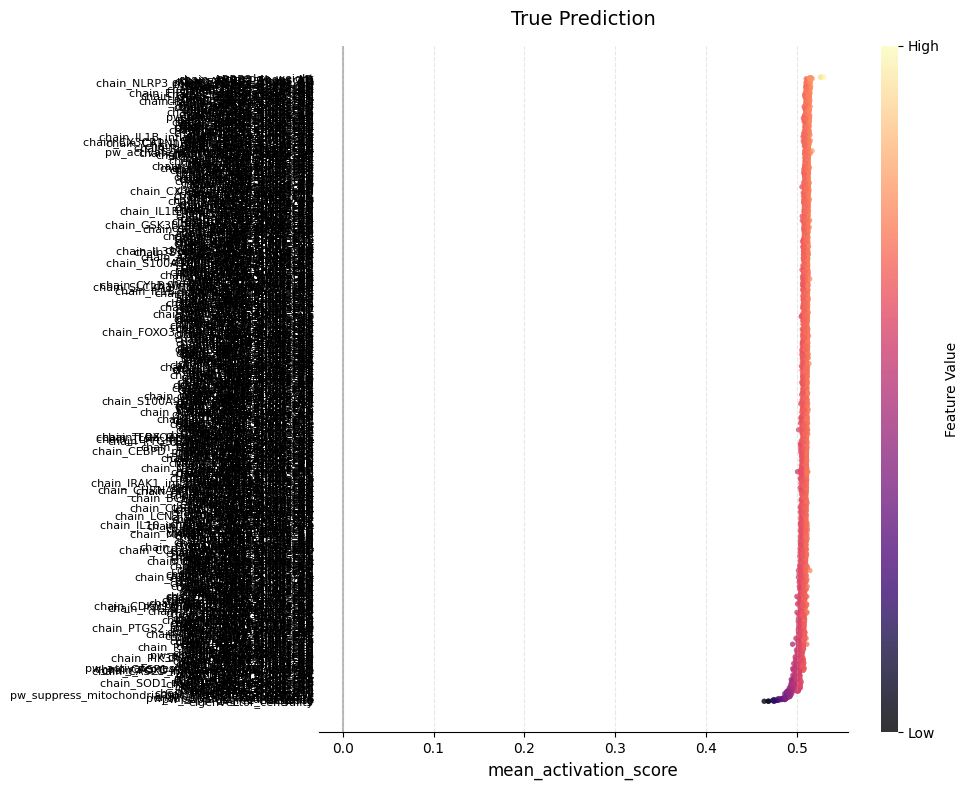

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:953: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_correct_means = df_correct.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:955: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_wrong_means = df_wrong.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation_score:
['pw_suppress_neuron death', 'chain_TNFRSF1B_5hops_AD', 'chain_TNFRSF1B_5hops_CTL', 'direct_TNFRSF1B_CTL', 'chain_TNFRSF1B_4hops_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules/ANMerge_FuzzyGAT_topo_all_rules_mean_activation_score_False Prediction.png


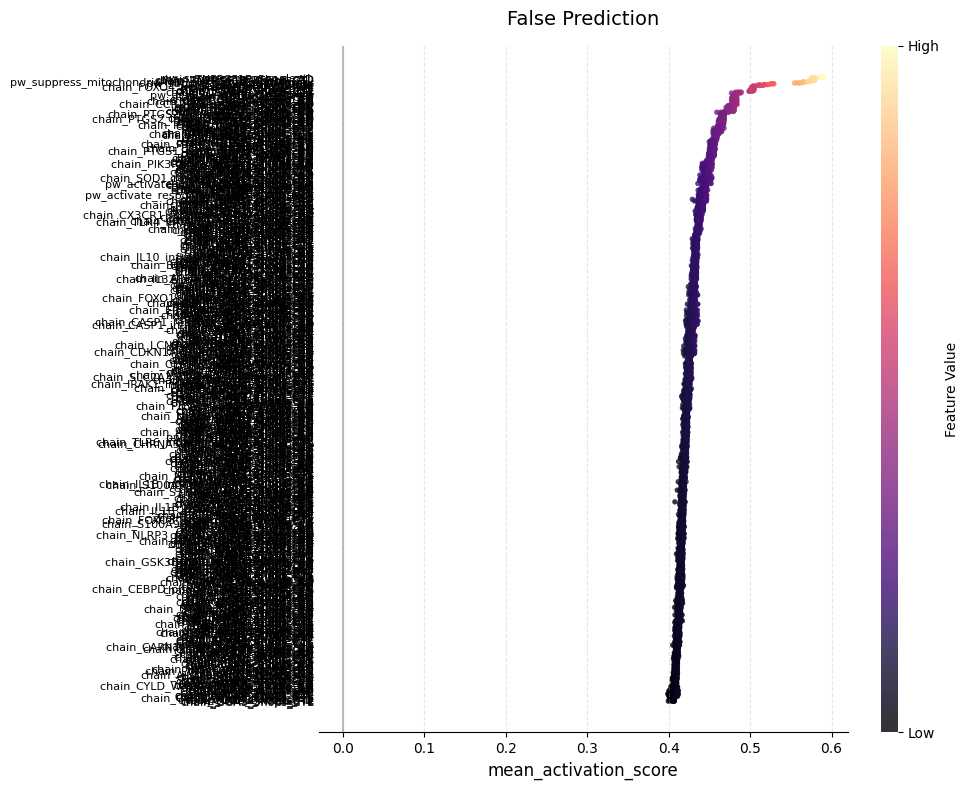

In [10]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_topo_all_rules"
save_dir = "../nesy_gnn/results/explain/AD_KG/ANMerge/4/rules"

df_all_t = plot_wrong_correct_mean_rulescore(df_samples=df_all_activation, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name='mean_activation_score',
                                        plot_correct=True,
                                        cmap='magma',
                                        save_dir=save_dir)

df_all_f = plot_wrong_correct_mean_rulescore(df_samples=df_all_activation, 
                                        dataset=dataset, 
                                        model_type=model_type, 
                                        k=k,
                                        rule_value_name='mean_activation_score',
                                        plot_correct=False,
                                        cmap='magma',
                                        save_dir=save_dir)

# Rule Activation on Confusion Matrix Cohort Analysis(TP/TN/FP/FN)

In [3]:
df_rules = pd.read_csv("../nesy_gnn/results/explain/AD_KG/ANMerge/4/KGRules.csv", 
                       index_col=0)
df_rules

,name,type,conclusion,n_genes,genes,bp,confidence,evidence
0,chain_SORL1_APP_CTL,direct_gene_ad,CTL,1,SORL1,NaN,0.80,"g(HGNC:""SORL1"") → APP → Alzheimer Disease (net..."
1,chain_MME_APP_CTL,direct_gene_ad,CTL,1,MME,NaN,0.80,"p(HGNC:""MME"") → APP → Alzheimer Disease (net s..."
2,chain_CTSD_APP_AD,direct_gene_ad,AD,1,CTSD,NaN,0.80,"g(HGNC:""CTSD"",var(""C,224,T"")) → APP → Alzheime..."
3,direct_BIN1_AD,direct_gene_ad,AD,1,BIN1,NaN,1.00,"g(HGNC:""BIN1"") --rev_positive_correlation--> p..."
4,direct_PICALM_AD,direct_gene_ad,AD,1,PICALM,NaN,1.00,"g(HGNC:""PICALM"") --rev_positive_correlation-->..."
...,...,...,...,...,...,...,...,...
736,chain_AKAP13_4hops_AD,causal_chain,AD,1,AKAP13,NaN,0.60,AKAP13 → MAPT → APP → Alzheimer Disease
737,chain_VPS35_5hops_AD,causal_chain,AD,1,VPS35,NaN,0.45,VPS35 → APP → APP → TNF → Alzheimer Disease
738,chain_VPS35_5hops_CTL,causal_chain,CTL,1,VPS35,NaN,0.45,VPS35 → APP → APP → nitric oxide → Alzheimer D...
739,chain_VPS35_4hops_AD,causal_chain,AD,1,VPS35,NaN,0.60,VPS35 → APP → APP → Alzheimer Disease


/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['direct_ITGAM_AD', 'direct_GAB2_AD', 'direct_ABCA7_AD', 'chain_SP1_amyloid-beta_AD', 'chain_ABCA7_APP_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_mean_activation_True Positive Prediction.png


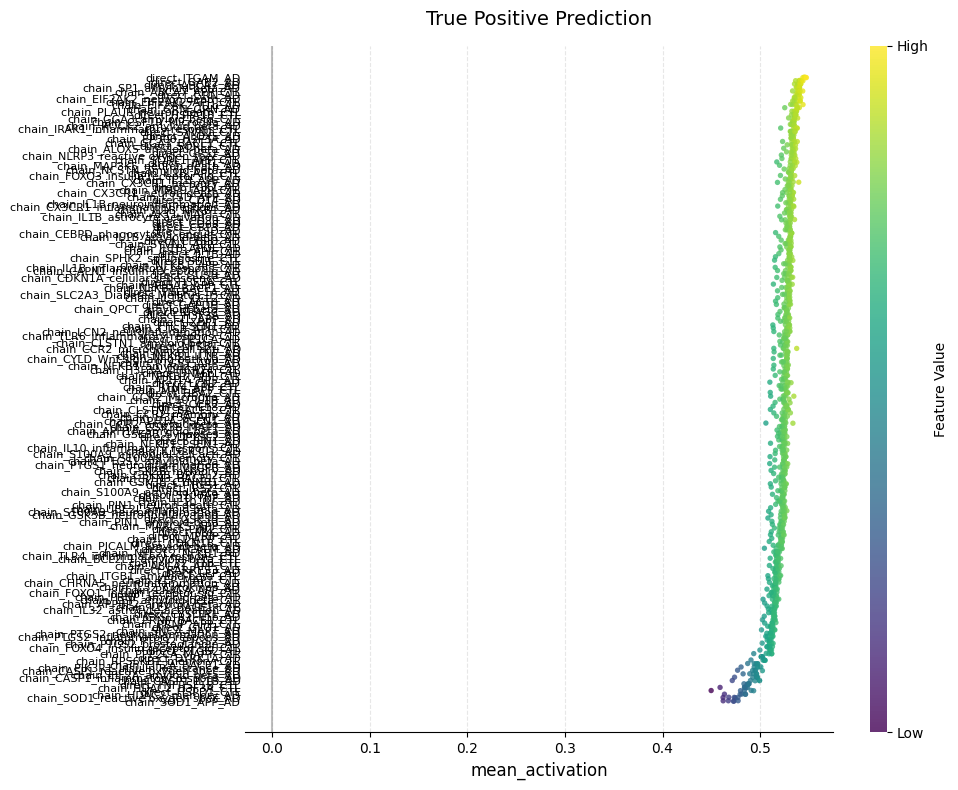

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_APP_AD', 'chain_HDAC2_H3F3A_CTL', 'chain_HDAC2_memory_AD', 'chain_EIF2A_BACE1_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_mean_activation_True Negative Prediction.png


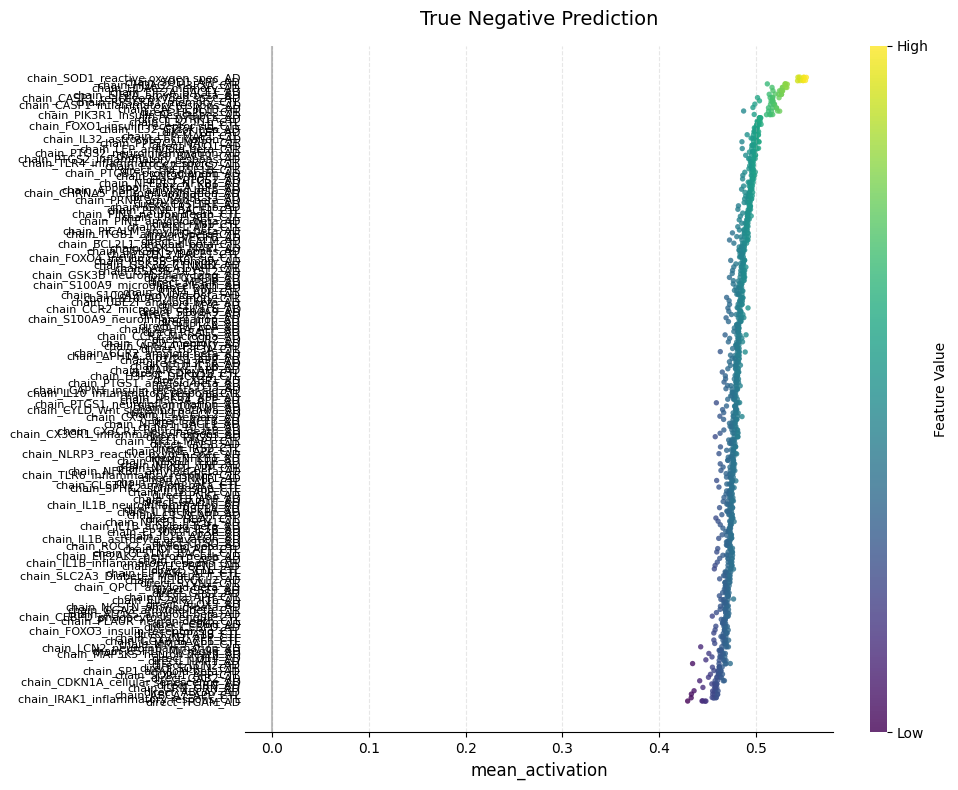

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['direct_TNFRSF1B_CTL', 'chain_FOXO4_insulin receptor sig_CTL', 'chain_PTGS1_APP_AD', 'chain_PTGS1_amyloid-beta_AD', 'chain_PTGS1_neuroinflammation_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_mean_activation_False Positive Prediction.png


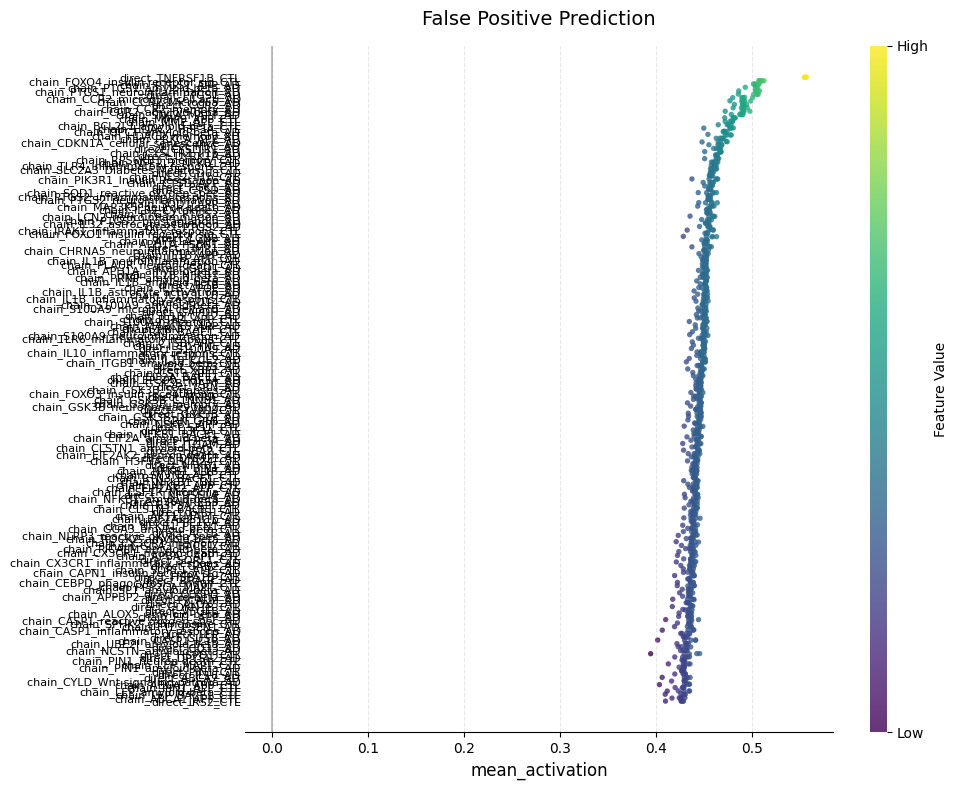

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['direct_TNFRSF1B_CTL', 'chain_FOXO4_insulin receptor sig_CTL', 'chain_CCR2_microglial cell acti_AD', 'chain_CCR2_Microglia_AD', 'direct_CCR2_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_direct_rules_mean_activation_False Negative Prediction.png


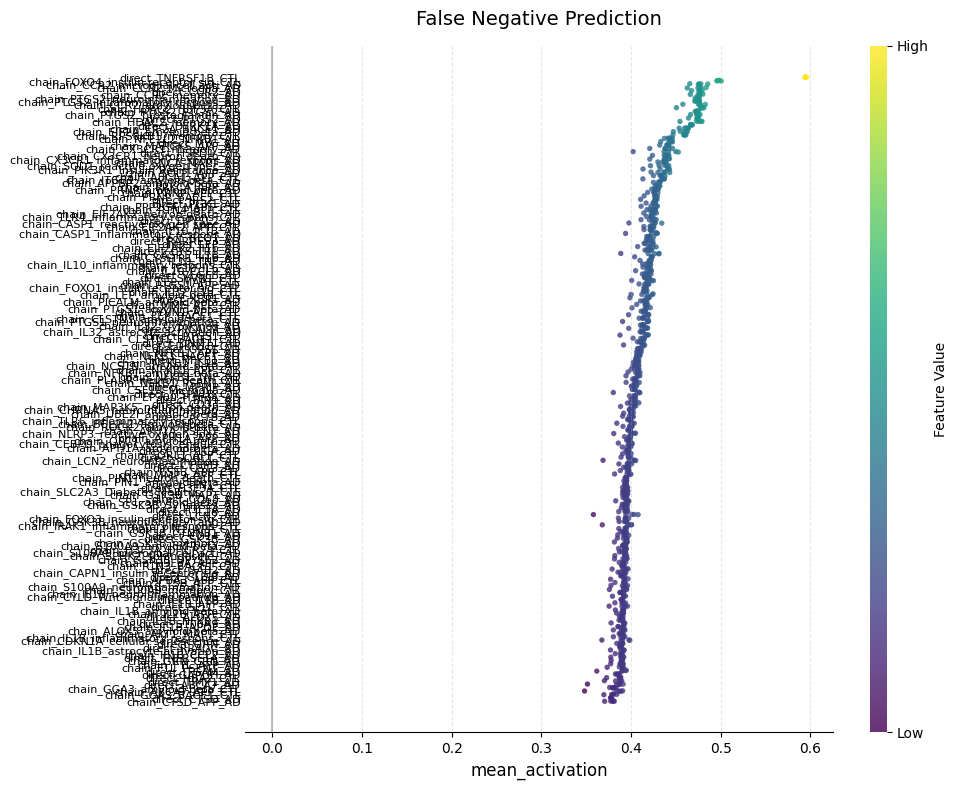

In [21]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"
rule_value_name = 'mean_activation'
save_dir = '../nesy_gnn/results/explain/AD_KG/rules'

df_dtp = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=True,
                                               xlim=None,
                                               x_interval=None,
                                               save_dir=save_dir)

df_dtn = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=False,
                                               xlim=None,
                                               x_interval=None,
                                               save_dir=save_dir)
df_dfp = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=True,
                                               xlim=None,
                                                x_interval=None,
                                                save_dir=save_dir)
df_dfn = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=False,
                                               xlim=None,
                                                x_interval=None,
                                                save_dir=save_dir)

In [22]:
dfs = [df_dtp, df_dtn, df_dfp, df_dfn]
df_names = ['TP','TN','FP','FN']

for i, df in enumerate(dfs):
    mean = df['mean_activation'].mean()
    print(f"\n{df_names[i]} mean = {mean}")
    for j, row in df.iterrows():
       print(f"{row['rule_name']}: {round(row['mean_activation'], ndigits=4)}")
       if j > 9:
           break


TP mean = 0.5217078398497325
direct_ITGAM_AD: 0.5459
direct_GAB2_AD: 0.5406
direct_ABCA7_AD: 0.5392
chain_SP1_amyloid-beta_AD: 0.5391
chain_ABCA7_APP_CTL: 0.5391
direct_GRN_AD: 0.5389
chain_EIF2AK2_neuron death_AD: 0.5376
chain_EIF2AK2_APP_CTL: 0.5376
chain_EIF2AK2_Il1b_AD: 0.5365
chain_GRN_GRN_AD: 0.5359
chain_PLAUR_neuron death_CTL: 0.5357

TN mean = 0.4811083775624875
chain_SOD1_reactive oxygen spec_AD: 0.5483
chain_SOD1_APP_AD: 0.5478
chain_HDAC2_H3F3A_CTL: 0.5274
chain_HDAC2_memory_AD: 0.5272
chain_EIF2A_BACE1_AD: 0.5249
chain_EIF2A_amyloid-beta_AD: 0.5223
chain_CASP1_reactive oxygen spec_AD: 0.5152
chain_RPS6KB1_memory_CTL: 0.5146
chain_CASP1_inflammatory respons_AD: 0.5144
chain_CASP1_IL1B_AD: 0.5142
direct_HSPD1_CTL: 0.513

FP mean = 0.44809205673497127
direct_TNFRSF1B_CTL: 0.5558
chain_FOXO4_insulin receptor sig_CTL: 0.5096
chain_PTGS1_APP_AD: 0.5044
chain_PTGS1_amyloid-beta_AD: 0.5024
chain_PTGS1_neuroinflammation_AD: 0.5018
direct_PTGS1_AD: 0.5011
chain_CCR2_microglial cell

+ FuzzyGAT_all_rules

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['direct_ITGAM_AD', 'chain_ITGAM_4hops_AD', 'chain_ITGAM_5hops_AD', 'chain_ITGAM_5hops_CTL', 'chain_PRKD2_5hops_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_all_rules_mean_activation_True Positive Prediction.png


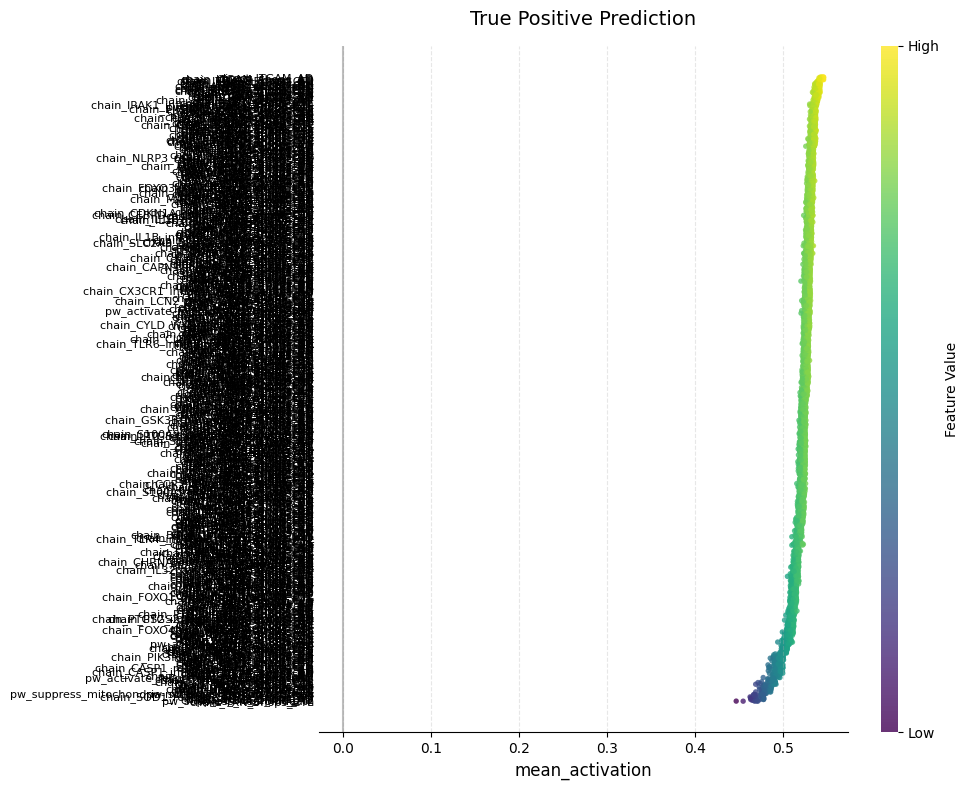

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['chain_TXN_5hops_CTL', 'chain_SOD1_reactive oxygen spec_AD', 'chain_SOD1_4hops_AD', 'chain_SOD1_5hops_CTL', 'chain_SOD1_3hops_AD']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_all_rules_mean_activation_True Negative Prediction.png


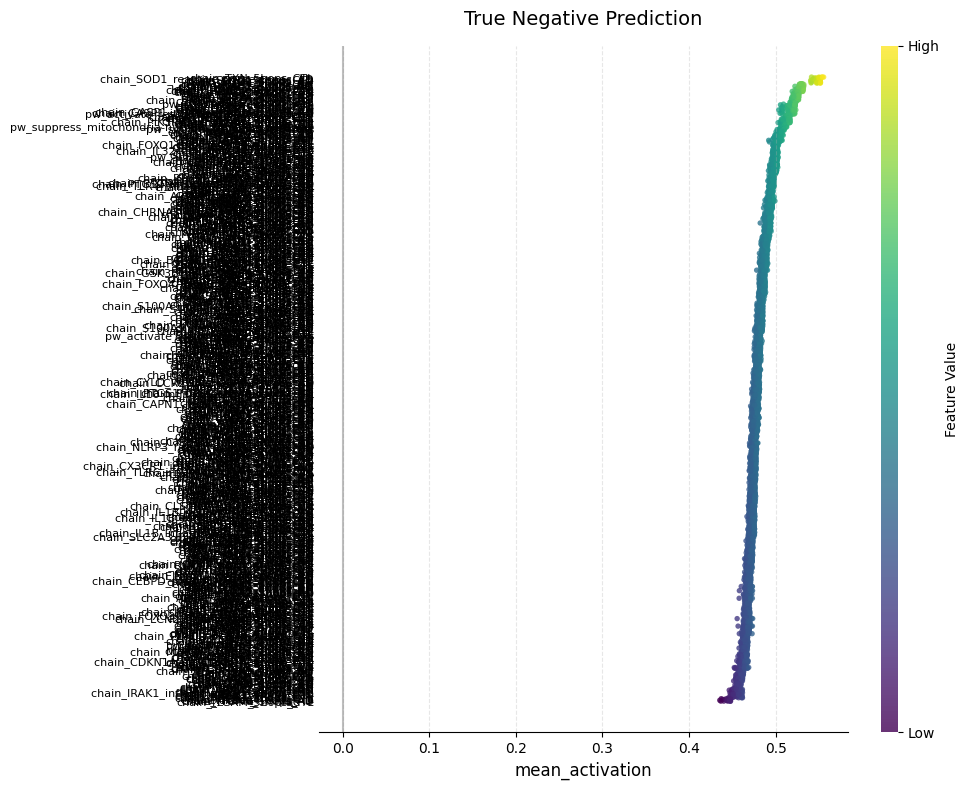

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['pw_suppress_neuron death', 'chain_TNFRSF1B_5hops_CTL', 'chain_TNFRSF1B_5hops_AD', 'direct_TNFRSF1B_CTL', 'chain_TNFRSF1B_4hops_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_all_rules_mean_activation_False Positive Prediction.png


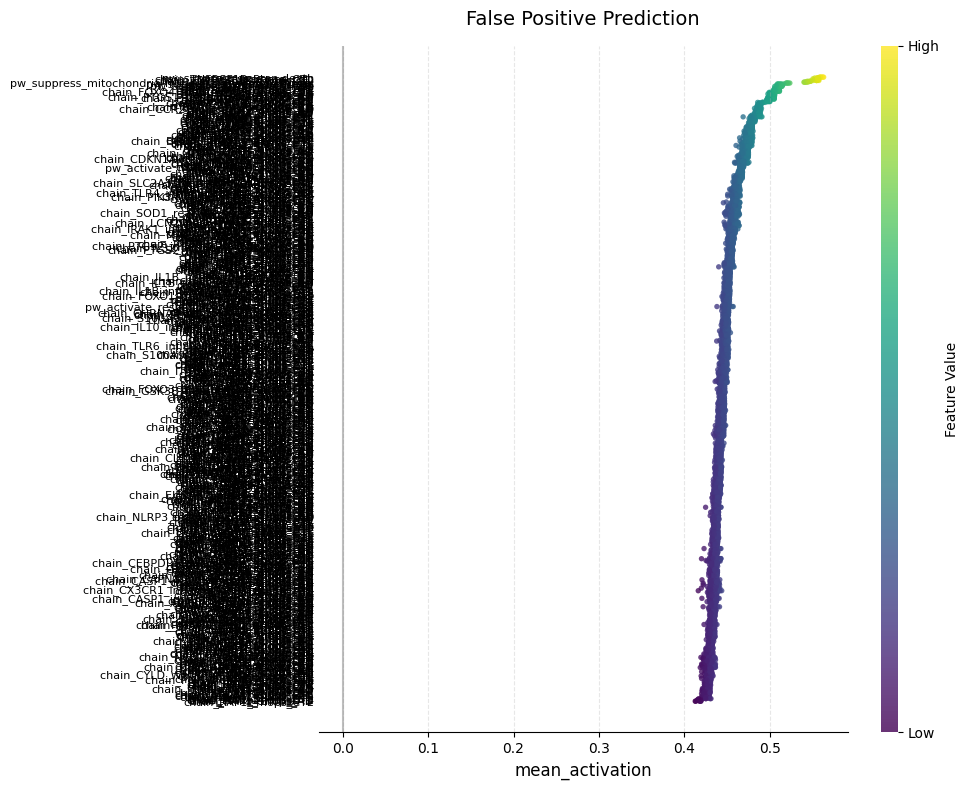

/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1041: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df1_means = df1.groupby(group_cols)[rule_cols].mean().reset_index()
/Users/yuxiaoxuan/master_thesis/HybridKG/nesy_gnn/post_analysis.py:1043: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df0_means = df0.groupby(group_cols)[rule_cols].mean().reset_index()


Top-5 rule_name by mean_activation:
['pw_suppress_neuron death', 'pw_suppress_Oxidative Stress', 'chain_TNFRSF1B_5hops_CTL', 'chain_TNFRSF1B_5hops_AD', 'direct_TNFRSF1B_CTL']
Saved plot to ../nesy_gnn/results/explain/AD_KG/rules/ANMerge_FuzzyGAT_all_rules_mean_activation_False Negative Prediction.png


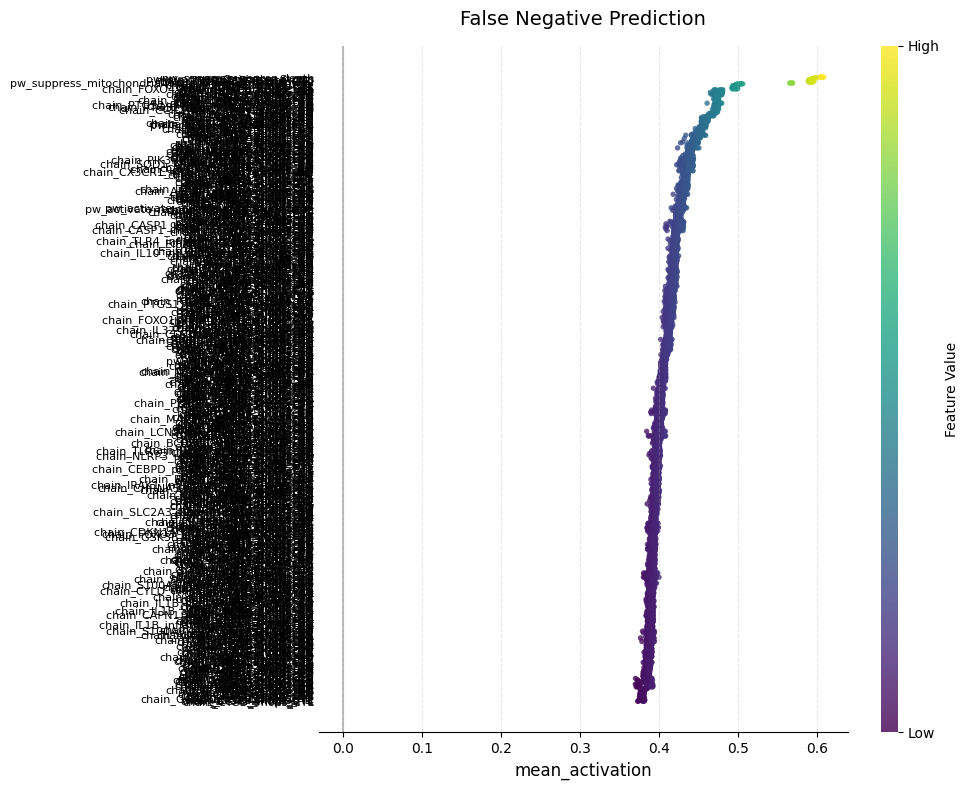

In [23]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_all_rules"
rule_value_name = 'mean_activation'
save_dir = '../nesy_gnn/results/explain/AD_KG/rules'

df_dtp = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=True,
                                               xlim=None,
                                               x_interval=None,
                                               save_dir=save_dir)

df_dtn = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=True,
                                               plot_disease=False,
                                               xlim=None,
                                               x_interval=None,
                                               save_dir=save_dir)
df_dfp = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=True,
                                               xlim=None,
                                                x_interval=None,
                                                save_dir=save_dir)
df_dfn = plot_tp_fn_rule_score(df_samples=df_all_activation,
                                               df_rules=df_rules,
                                               dataset=dataset,
                                               k=k,
                                               model_type=model_type,
                                               rule_value_name=rule_value_name,
                                               plot_correct=False,
                                               plot_disease=False,
                                               xlim=None,
                                                x_interval=None,
                                                save_dir=save_dir)

In [24]:
dfs = [df_dtp, df_dtn, df_dfp, df_dfn]
df_names = ['TP','TN','FP','FN']

for i, df in enumerate(dfs):
    mean = df['mean_activation'].mean()
    print(f"\n{df_names[i]} mean = {mean}")
    for j, row in df.iterrows():
       print(f"{row['rule_name']}:{round(row['mean_activation'],4)}")
       if j > 9:
           break


TP mean = 0.5209883847953526
direct_ITGAM_AD:0.544
chain_ITGAM_4hops_AD:0.5434
chain_ITGAM_5hops_AD:0.5433
chain_ITGAM_5hops_CTL:0.5433
chain_PRKD2_5hops_AD:0.5405
direct_GAB2_AD:0.54
chain_ABCA7_5hops_AD:0.5396
chain_PRKD2_4hops_AD:0.5395
chain_GAB2_5hops_CTL:0.5392
direct_ABCA7_AD:0.5391
chain_ABCA7_4hops_CTL:0.5391

TN mean = 0.4818524180236687
chain_TXN_5hops_CTL:0.5508
chain_SOD1_reactive oxygen spec_AD:0.5487
chain_SOD1_4hops_AD:0.5487
chain_SOD1_5hops_CTL:0.5485
chain_SOD1_3hops_AD:0.5484
chain_SOD1_5hops_AD:0.5483
chain_SOD1_APP_AD:0.548
chain_SOD1_4hops_CTL:0.5479
chain_NAE1_4hops_AD:0.5296
chain_HDAC2_3hops_AD:0.5294
chain_NAE1_5hops_AD:0.5293

FP mean = 0.449417841976649
pw_suppress_neuron death:0.5608
chain_TNFRSF1B_5hops_CTL:0.5555
chain_TNFRSF1B_5hops_AD:0.5553
direct_TNFRSF1B_CTL:0.555
chain_TNFRSF1B_4hops_CTL:0.5545
pw_suppress_memory:0.5461
pw_suppress_mitochondria-nucleus signaling pathway:0.542
pw_suppress_Oxidative Stress:0.5211
chain_ADD3_5hops_AD:0.5123
pw_activa